# Comps and valuation

Steps 4-7 of the mentor's recipe for getting comps, building on `comp_universe_and_facets.ipynb` (steps 1-3):

4. **Suggest comps** for a target (an LLM or any other way).
5. **Profiles:** construct a company profile for the target and the comps. Here a target's **profile** is its collection of comps. A company's facets are its **business-model characteristics** (descriptive characteristics), not its profile.
6. **Score each comp** between 0 and 1: is it a good or bad comp? (an LLM, embeddings and cosine similarity, or any other way).
7. **Estimate:** a suitably weighted average of the comps' EV/EBITDA.

Plus the recipe's balanced 70/30 training/holdout split. The recipe's evals (manual review of target-comp pairs with a rubric) come later, in a separate notebook; `judgments.csv` (section 3) is the pair table it will start from.

How the recipe maps onto this notebook (decided 2026-10-25):

| section | recipe | here | status |
|---|---|---|---|
| 1 | split | 70/30, stratified on company size | built |
| 2 | 4. suggest comps, 5. profiles | embedding cosine similarity on the facets; each target's profile is its candidates, the top k or z ≥ 2 | built |
| 3 | 6. good or bad, 0-1 | **the model:** an LLM (Claude Haiku 5.5) marks each z ≥ 2 candidate good (1) or bad (0). Its prompt and any fitted weights are developed on the training firms. | built |
| 4 | 4 again, without embeddings | the LLM suggests comps directly from the whole training pool; and same-SIC peers, with no model at all | built |
| 5 | LLM then cosine | cosine reranks and weights the direct LLM selections | built |
| 6 | 7. weighted EV/EBITDA | the estimate against the actual multiples, for every way of finding comps, and against no matching | built |

**"Training" here means the 373 firms we may look at while developing, not a fitted model.** Nothing is fitted yet: every way of finding comps is run on every training target, and its estimates are compared with the actual multiples. The 160 holdout firms are kept for one final test.

Record each decision in its section (and in `v0/README.md`) before writing that section's code.

Runs in the `qual2cast` kernel (Python 3.14), which has `sentence-transformers`.

## 0. Inputs

- `universe.csv`: the 533 universe companies (steps 1-2), company information only.
- `facets.csv`: each company's business-model characteristics, facets F1-F12 (step 3), one row per company.
- `financials.csv`: LTM revenue, EBITDA, margin, debt/revenue and EV/EBITDA, in their own table keyed by `IQ_COMPANY_ID`.

Rules that already hold: EV/EBITDA is the answer, never read by the comp-finding steps. Here it is read only for the split's balance check (which assigns firms; nothing is fit on it), then in step 7 and the evaluation. On the target side, only name and website, plus LTM revenue, LTM EBITDA and debt (for scale). Comps may also use 10-K detail.

In [1]:
import json
import sys
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd

# repo root = the folder holding data_manifest.json (works from the repo root, v0/ or v0/notebooks/)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_manifest.json").exists())
sys.path.insert(0, str(ROOT / "v0"))
import facets as fc                     # also puts website_scrape/ and src/ on the path
import candidates as cd
import split as sp
import valuation as vl
from fill_facets import DEFAULT_OUT as FACETS_OUT, output_paths
from project_data import OUTPUTS_LOCAL

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

RUN = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
COMPS_OUT = OUTPUTS_LOCAL / "comps"

# latest universe run (steps 1-2) and the current facet table (step 3)
UNIVERSE_RUN = sorted(p for p in (COMPS_OUT / "universe").iterdir() if (p / "universe.csv").exists())[-1]
universe = pd.read_csv(UNIVERSE_RUN / "universe.csv", dtype=str)
facets = pd.read_csv(output_paths(FACETS_OUT).tables / "facets.csv", dtype=str).fillna("")
facets = facets[(facets["prompt_version"] == fc.PROMPT_VERSION) & (facets["llm_status"] == "ok")]
# financials stay in their own table
financials = pd.read_csv(UNIVERSE_RUN / "financials.csv", dtype={"IQ_COMPANY_ID": str}).set_index("IQ_COMPANY_ID")
financials = financials.loc[universe["IQ_COMPANY_ID"]]
id_of = dict(zip(universe["target_ciq_ticker"], universe["IQ_COMPANY_ID"]))
info = universe.set_index("IQ_COMPANY_ID")
print(f"universe run {UNIVERSE_RUN.name}: {len(universe)} companies; facets version {fc.PROMPT_VERSION}: "
      f"{facets['IQ_COMPANY_ID'].nunique()} companies, {len(facets)} rows of facets; financials: {len(financials)} rows")

universe run 20261025T060358Z: 533 companies; facets version 2026-10-25k: 533 companies, 533 rows of facets; financials: 533 rows


## Design decisions

| # | decision | status |
|---|---|---|
| D1 | **What kind of model** | **Decided 2026-10-25:** prompts plus weights fit on training pairs. No fine-tuning. |
| D2 | **What the weights are fit to** (a "good comp" label) | open: human rubric labels (the recipe's manual review), closeness of the two multiples, or both |
| D3 | **Candidates in step 4** | **Decided 2026-10-25:** embedding cosine similarity, as in pre-v0, on the facets. Candidates are the top k, or those at or above a z-score level. |
| D4 | **Who can be a comp** | **Decided 2026-10-25:** training firms only during development. Holdout targets get comps from the training firms at the end. |
| D5 | **Profile in step 5** | **Decided 2026-10-25:** a target's profile is its collection of comps, the step 4 candidates (section 2) |
| D6 | **Score in step 6** | **Decided 2026-10-25:** the LLM marks each z ≥ 2 candidate good (1) or bad (0), with a short reason (section 3). A rubric with more levels waits for the evals. |
| D7 | **What the LLM reads** | **Decided 2026-10-25:** names, websites and all twelve facets of the target and the candidates, the candidates in alphabetical order with no similarity, rank or multiple. Open: 10-K detail, the target's revenue, EBITDA and debt. |
| D9 | **Weights in step 7** | similarity-weighted mean for cosine comps and LLM→cosine; equal weights for direct LLM and same-SIC comps (section 6). Open: weights fit on training pairs, and what to do for a target with no comp. |
| D10 | **Comps without embeddings** | **Tested 2026-10-25** (section 4): the LLM picks up to ten comps from the whole training pool; and same-SIC peers |
| D8 | **The split** | **Decided 2026-10-25:** stratified on company size (F9), 70/30, seed 2026, the ten showcase targets in training |

## Why a holdout

The holdout answers one question: **how wrong is the estimate for a company the method was never adjusted on?** Training error can't answer it. Every choice made by looking at results (a prompt edit, a threshold, k, the weights) fits the method to those companies.

With D1 (prompts plus fitted weights), the training firms are where the LLM step's prompts are changed and its weights are fit (section 3). The holdout is scored once, with everything frozen.

Rules this implies:
- Holdout firms aren't targets during development, and their multiples aren't used. So during development they aren't comps either (D4).
- The holdout targets are scored once, at the end. Their comps come from the training firms, as in a real deal: the comps are known and the target is new.
- The manual review used to tune the LLM step comes from training targets; a separate sample from the holdout checks the final comps.

What it can't fix: the LLM may already know public companies' valuations from its training. No prompt shows a multiple, but the model could still lean on what it remembers. The real targets are private, so it can't do that for them.

## 1. Training / holdout split

**Decided 2026-10-25:**
- 70/30, stratified on **company size** (F9: small, mid-sized, large, among the largest; the companies whose size is unknown form their own stratum). Each size category is split 70/30, with the per-category counts rounded so the total is 373 training firms.
- **Seed 2026**, recorded with the split. It is not re-drawn to improve the balance below.
- The **ten showcase targets** are in training, because they are examined during development. They count toward their size category's 70%.
- **Balance check** on what isn't stratified: SIC division shares, and standardized mean differences (SMD) of log revenue, EBITDA margin, debt/revenue and EV/EBITDA. Under about 0.1 is balanced.
- Saved to `outputs-local/comps/split/<run>/`.

In [2]:
SHOWCASE = ["PCTY", "BV", "ROAD", "LMB", "BRO", "ADUS", "DXPE", "SLGN", "BGS", "WEN"]
assert set(SHOWCASE) <= set(id_of), set(SHOWCASE) - set(id_of)

strata = sp.size_strata(facets).reindex(universe["IQ_COMPANY_ID"]).fillna(sp.SIZE_UNKNOWN)
sample = sp.stratified_split(strata, sp.TRAIN_SHARE, sp.SEED, forced_train=[id_of[t] for t in SHOWCASE])
split = universe[["IQ_COMPANY_ID", "target_ciq_ticker", "target_company_name", "target_sic2_code"]].assign(
    size_stratum=universe["IQ_COMPANY_ID"].map(strata), sample=universe["IQ_COMPANY_ID"].map(sample),
    showcase=universe["target_ciq_ticker"].isin(SHOWCASE))
training = split.loc[split["sample"] == "training", "IQ_COMPANY_ID"].tolist()
print(f"seed {sp.SEED}: {len(training)} training, {(split['sample'] == 'holdout').sum()} holdout")
pd.crosstab(split["size_stratum"], split["sample"], margins=True)[["training", "holdout", "All"]]

seed 2026: 373 training, 160 holdout


sample,training,holdout,All
size_stratum,,,
among the largest,51,22,73
large,193,83,276
mid-sized,114,49,163
small,13,6,19
unknown,2,0,2
All,373,160,533


In [3]:
s = split.set_index("IQ_COMPANY_ID")["sample"]
division = split.set_index("IQ_COMPANY_ID")["target_sic2_code"].map(sp.sic_division)
f = financials
numeric = {"log revenue": np.log(f["target_revenue"].where(f["target_revenue"] > 0)),
           "EBITDA margin": f["target_margin"], "debt / revenue": f["target_debt_to_revenue"],
           "EV/EBITDA": f["target_ev_to_ebitda"]}
balance_size = sp.share_balance(s, split.set_index("IQ_COMPANY_ID")["size_stratum"])
balance_sector = sp.share_balance(s, division)
balance_numeric = sp.numeric_balance(s, numeric)
print("% of each sample by company size (stratified, so equal up to rounding):")
display(balance_size.round(1))
print("% of each sample by SIC division:")
display(balance_sector.round(1))
print(f"numeric variables (|SMD| < 0.1 is balanced; largest here {balance_numeric['SMD'].abs().max():.3f}):")
display(balance_numeric.round(3))

% of each sample by company size (stratified, so equal up to rounding):


sample,training,holdout,difference
size_stratum,,,
among the largest,13.7,13.8,-0.1
large,51.7,51.9,-0.1
mid-sized,30.6,30.6,-0.1
small,3.5,3.8,-0.3
unknown,0.5,0.0,0.5


% of each sample by SIC division:


sample,training,holdout,difference
target_sic2_code,,,
"A Agriculture, Forestry, Fishing",0.3,0.0,0.3
B Mining,1.1,1.2,-0.2
C Construction,5.1,1.2,3.8
D Manufacturing,33.2,38.8,-5.5
"E Transportation, Communications, Utilities",7.5,7.5,0.0
F Wholesale Trade,2.9,2.5,0.4
G Retail Trade,3.2,3.1,0.1
"H Finance, Insurance, Real Estate",10.7,12.5,-1.8
I Services,35.9,33.1,2.8


numeric variables (|SMD| < 0.1 is balanced; largest here 0.126):


,training mean,holdout mean,training median,holdout median,SMD
variable,,,,,
log revenue,7.088,7.034,7.122,7.025,0.040
EBITDA margin,0.205,0.199,0.182,0.178,0.055
debt / revenue,0.688,0.597,0.441,0.400,0.126
EV/EBITDA,11.718,11.725,10.426,11.063,-0.001


In [4]:
SPLIT_OUT = COMPS_OUT / "split" / RUN
SPLIT_OUT.mkdir(parents=True, exist_ok=True)
split.to_csv(SPLIT_OUT / "split.csv", index=False)
balance_size.to_csv(SPLIT_OUT / "balance_size.csv")
balance_sector.to_csv(SPLIT_OUT / "balance_sector.csv")
balance_numeric.to_csv(SPLIT_OUT / "balance_numeric.csv")
(SPLIT_OUT / "run.json").write_text(json.dumps({
    "run": RUN, "universe_run": UNIVERSE_RUN.name, "facets_version": fc.PROMPT_VERSION,
    "stratified_on": "company_size (F9)", "train_share": sp.TRAIN_SHARE, "seed": sp.SEED,
    "showcase_in_training": SHOWCASE,
    "counts": split.groupby(["size_stratum", "sample"]).size().unstack(fill_value=0).to_dict("index"),
    "max_abs_smd": round(float(balance_numeric["SMD"].abs().max()), 4),
}, indent=1), encoding="utf-8")
print("wrote", SPLIT_OUT.relative_to(ROOT))

wrote outputs-local\comps\split\20261025T080854Z


## 2. Step 4: suggest comps

**Decided 2026-10-25:** embedding similarity, as in pre-v0 method 1 (`v0/candidates.py`).

- Every universe company's facets are embedded with `all-mpnet-base-v2`, **one facet at a time**. All twelve facets together (105-295 words) come close to the model's 384-token limit, and per-facet similarities are what the fitted weights (D1) will weight.
- **Similarity** of a target and a comp = the mean of their per-facet cosines, over the facets both have. The weights are **equal for now**; fitting them on training pairs replaces them later. Company size (F9) is left out: it is scale, which the target's financials cover, and the split is stratified on it. A facet that doesn't apply (no products) is embedded as "none".
- **Pool:** for a training target, the other training firms (D4). Holdout targets are not ranked here.
- **z** = (similarity − the target's mean over the pool) / SD, as in pre-v0. **Candidates** are the top k (k = 10), or any firm with z ≥ 2 (pre-v0's two levels, 2 and 2.5, are both flagged). The LLM step (section 3) decides which are good.
- **Recipe step 5, profiles:** a target's profile is its collection of comps, these candidates (`candidates.csv`, median 14 per target). Step 4 builds them by comparing the target's business-model characteristics (the facets) with every pool firm's, facet by facet, so step 5 needs nothing more.
- The cosine similarity (0.11 to 0.90 over all training pairs) is also a 0-1 score for each comp: the comparison without the LLM in section 4 weights by it.

The embeddings are cached in `outputs-local/comps/embeddings/`, keyed by the model and the facet texts, so a rerun with the same facets doesn't embed again. When they have to be made, the model is loaded from the local Hugging Face cache, with no Hub request (it is downloaded only once, if missing).

In [5]:
texts = cd.facet_texts(facets).reindex(universe["IQ_COMPANY_ID"])
ids = list(texts.index)
embeddings, embed_cache = cd.embed_facets(texts, COMPS_OUT / "embeddings")
S, per_facet = cd.similarity(embeddings)
print(f"{len(ids)} companies x {len(embeddings)} facets, {next(iter(embeddings.values())).shape[1]} dimensions; "
      f"cache {embed_cache.name}")
print("facets in the similarity:", ", ".join(f"{fc.FACET_ID[n]} {n}" for n in cd.SIMILARITY_FACETS))

533 companies x 11 facets, 768 dimensions; cache facets_all-mpnet-base-v2_6f4ce4373bfbc08a.npz
facets in the similarity: F1 offering_description, F2 primary_products, F3 primary_services, F4 customer_segment, F5 end_markets, F6 revenue_model, F7 value_chain_position, F8 geography_served, F10 specialization, F11 distribution_channels, F12 regulatory_exposure


In [6]:
ranking = cd.rank_candidates(S, ids, targets=training, pool=training)
cands = cd.add_facet_similarities(cd.candidates(ranking), per_facet, ids)
for col, src in [("target_ticker", "target"), ("comp_ticker", "comp")]:
    cands.insert(cands.columns.get_loc(src) + 1, col, cands[src].map(info["target_ciq_ticker"]))
cands.insert(cands.columns.get_loc("comp_ticker") + 1, "comp_company", cands["comp"].map(info["target_company_name"]))

z_cols = [f"z_ge_{lvl:g}" for lvl in cd.Z_LEVELS]
per_target = ranking.groupby("target")[z_cols].sum()
for col in z_cols:
    n = per_target[col]
    print(f"{col}: median {n.median():.0f} comps per target, range {n.min()}-{n.max()}; "
          f"{(n < 3).sum()} of {len(n)} targets have fewer than 3")
print(f"candidates (top {cd.TOP_K} or z >= {min(cd.Z_LEVELS):g}): {len(cands)} pairs, "
      f"{cands.groupby('target').size().median():.0f} per target (median)")

# sanity check (as in pre-v0): how often a top-k candidate shares the target's SIC2, against random pairs
sic2 = info["target_sic2_code"]
top = ranking[ranking["in_top_k"]]
same = (top["comp"].map(sic2).to_numpy() == top["target"].map(sic2).to_numpy()).mean()
pool_sic = sic2[training].to_numpy()
chance = np.mean([((pool_sic == c).sum() - 1) / (len(pool_sic) - 1) for c in pool_sic])
print(f"top-{cd.TOP_K} candidates sharing the target's SIC2: {same:.1%} (random pairs: {chance:.1%})")

z_ge_2: median 14 comps per target, range 5-23; 0 of 373 targets have fewer than 3
z_ge_2.5: median 7 comps per target, range 0-15; 28 of 373 targets have fewer than 3
candidates (top 10 or z >= 2): 5363 pairs, 14 per target (median)
top-10 candidates sharing the target's SIC2: 46.6% (random pairs: 7.2%)


The showcase targets' candidates, most similar first. Columns `z_ge_2` and `z_ge_2.5` mark the z levels; rows past rank 10 are there because their z is at least 2.

In [7]:
show_cols = ["rank", "comp_ticker", "comp_company", "similarity", "z", "in_top_k", *z_cols]
for t in SHOWCASE:
    rows = cands[cands["target_ticker"] == t]
    print(f"{t} ({info.loc[id_of[t], 'target_company_name']}, SIC {info.loc[id_of[t], 'target_sic4_code']}): "
          f"{len(rows)} candidates, {rows['z_ge_2'].sum()} at z >= 2")
    display(rows[show_cols].set_index("rank").round({"similarity": 3, "z": 2}))

PCTY (Paylocity Holding Corporation, SIC 7370): 14 candidates, 14 at z >= 2


,comp_ticker,comp_company,similarity,z,in_top_k,z_ge_2,z_ge_2.5
rank,,,,,,,
1,ASUR,"Asure Software, Inc.",0.855,4.76,True,True,True
2,PAYC,"Paycom Software, Inc.",0.830,4.50,True,True,True
3,ADP,"Automatic Data Processing, Inc.",0.761,3.75,True,True,True
4,ALIT,"Alight, Inc.",0.733,3.45,True,True,True
5,UPLD,"Upland Software, Inc.",0.683,2.91,True,True,True
6,SSNC,"SS&C Technologies Holdings, Inc.",0.664,2.71,True,True,True
7,INTU,Intuit Inc.,0.662,2.69,True,True,True
8,EVCM,EverCommerce Inc.,0.657,2.64,True,True,True
9,CXM,"Sprinklr, Inc.",0.642,2.48,True,True,False


BV (BrightView Holdings, Inc., SIC 0700): 10 candidates, 10 at z >= 2


,comp_ticker,comp_company,similarity,z,in_top_k,z_ge_2,z_ge_2.5
rank,,,,,,,
1,LGN,Legence Corp.,0.649,2.90,True,True,True
2,APG,APi Group Corporation,0.642,2.81,True,True,True
3,LMB,"Limbach Holdings, Inc.",0.629,2.64,True,True,True
4,BWMN,Bowman Consulting Group Ltd.,0.614,2.44,True,True,False
5,IESC,"IES Holdings, Inc.",0.610,2.38,True,True,False
6,ROAD,"Construction Partners, Inc.",0.607,2.34,True,True,False
7,JOE,The St. Joe Company,0.607,2.34,True,True,False
8,GVA,Granite Construction Incorporated,0.601,2.26,True,True,False
9,CDNL,Cardinal Infrastructure Group Inc.,0.594,2.18,True,True,False


ROAD (Construction Partners, Inc., SIC 1600): 12 candidates, 12 at z >= 2


...

,comp_ticker,comp_company,similarity,z,in_top_k,z_ge_2,z_ge_2.5
rank,,,,,,,
1,REYN,Reynolds Consumer Products Inc.,0.740,3.21,True,True,True
2,PACK,Ranpak Holdings Corp.,0.691,2.71,True,True,True
3,SENE.A,Seneca Foods Corporation,0.689,2.68,True,True,True
4,BGS,"B&G Foods, Inc.",0.683,2.61,True,True,True
5,ASH,Ashland Inc.,0.683,2.61,True,True,True
6,HRL,Hormel Foods Corporation,0.668,2.47,True,True,False
7,COKE,"Coca-Cola Consolidated, Inc.",0.665,2.43,True,True,False
8,EMN,Eastman Chemical Company,0.660,2.38,True,True,False
9,LW,"Lamb Weston Holdings, Inc.",0.658,2.36,True,True,False


BGS (B&G Foods, Inc., SIC 2000): 18 candidates, 18 at z >= 2


,comp_ticker,comp_company,similarity,z,in_top_k,z_ge_2,z_ge_2.5
rank,,,,,,,
1,SENE.A,Seneca Foods Corporation,0.880,4.12,True,True,True
2,HRL,Hormel Foods Corporation,0.835,3.71,True,True,True
3,FIZZ,National Beverage Corp.,0.803,3.42,True,True,True
4,FRPT,"Freshpet, Inc.",0.798,3.38,True,True,True
5,MKC,"McCormick & Company, Incorporated",0.797,3.37,True,True,True
6,LW,"Lamb Weston Holdings, Inc.",0.794,3.33,True,True,True
7,REYN,Reynolds Consumer Products Inc.,0.783,3.24,True,True,True
8,STKL,SunOpta Inc.,0.761,3.04,True,True,True
9,SMPL,The Simply Good Foods Company,0.760,3.03,True,True,True


WEN (The Wendy's Company, SIC 5812): 19 candidates, 19 at z >= 2


,comp_ticker,comp_company,similarity,z,in_top_k,z_ge_2,z_ge_2.5
rank,,,,,,,
1,BROS,Dutch Bros Inc.,0.731,4.35,True,True,True
2,NATH,"Nathan's Famous, Inc.",0.683,3.76,True,True,True
3,STKS,"The ONE Group Hospitality, Inc.",0.649,3.35,True,True,True
4,BGS,"B&G Foods, Inc.",0.645,3.29,True,True,True
5,HRL,Hormel Foods Corporation,0.638,3.20,True,True,True
6,SMPL,The Simply Good Foods Company,0.627,3.08,True,True,True
7,LW,"Lamb Weston Holdings, Inc.",0.620,2.98,True,True,True
8,SENE.A,Seneca Foods Corporation,0.618,2.96,True,True,True
9,FIZZ,National Beverage Corp.,0.606,2.81,True,True,True


In [8]:
CAND_OUT = COMPS_OUT / "candidates" / RUN
CAND_OUT.mkdir(parents=True, exist_ok=True)
cands.to_csv(CAND_OUT / "candidates.csv", index=False)
ranking.to_csv(CAND_OUT / "ranking.csv.gz", index=False)
(CAND_OUT / "run.json").write_text(json.dumps({
    "run": RUN, "split_run": SPLIT_OUT.name, "universe_run": UNIVERSE_RUN.name, "facets_version": fc.PROMPT_VERSION,
    "embed_model": cd.EMBED_MODEL, "embedding_cache": embed_cache.name,
    "similarity_facets": cd.SIMILARITY_FACETS, "weights": "equal",
    "targets": "training", "pool": "training (not the target itself)",
    "top_k": cd.TOP_K, "z_levels": list(cd.Z_LEVELS), "candidate_rule": f"top {cd.TOP_K} or z >= {min(cd.Z_LEVELS):g}",
    "pairs": len(cands), "showcase": SHOWCASE,
}, indent=1), encoding="utf-8")
print("wrote", CAND_OUT.relative_to(ROOT))

wrote outputs-local\comps\candidates\20261025T080854Z


### Similarity fall-off, per showcase target

As in pre-v0: each target's similarity to every firm in its pool, most similar first (left), and the top 40 with the candidates labeled (right). The dashed lines are the similarities where z = 2 and z = 2.5; the dotted line is k = 10. Filled dots are at z ≥ 2.5, open blue dots at 2 ≤ z < 2.5, and open grey dots are in the top 10 below z = 2. A sharp drop after the first few firms means a clear peer group; a flat curve means the target has no close peers in the pool. Saved as `similarity_falloff_<ticker>.png` in the candidates run folder.

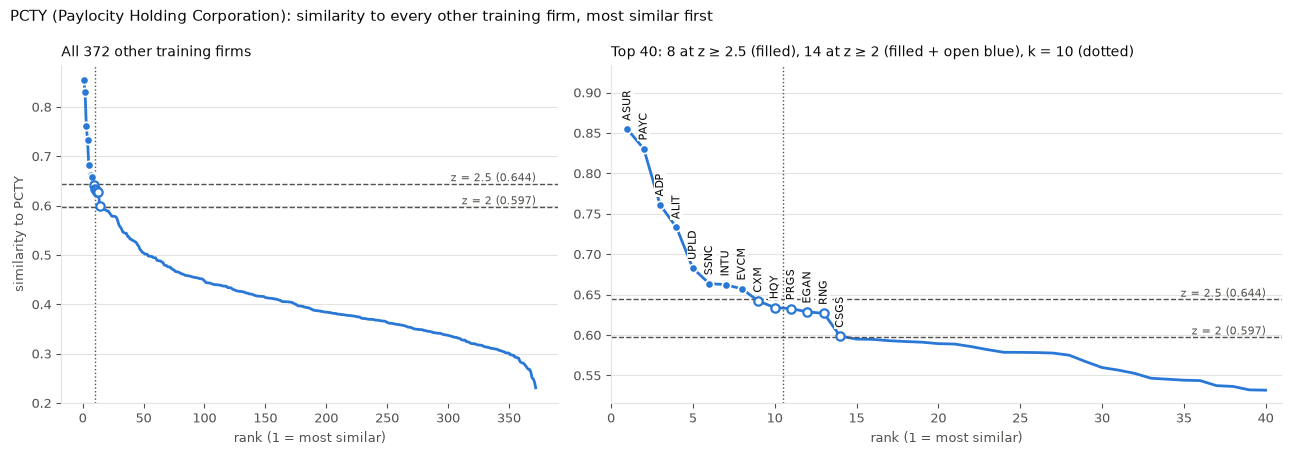

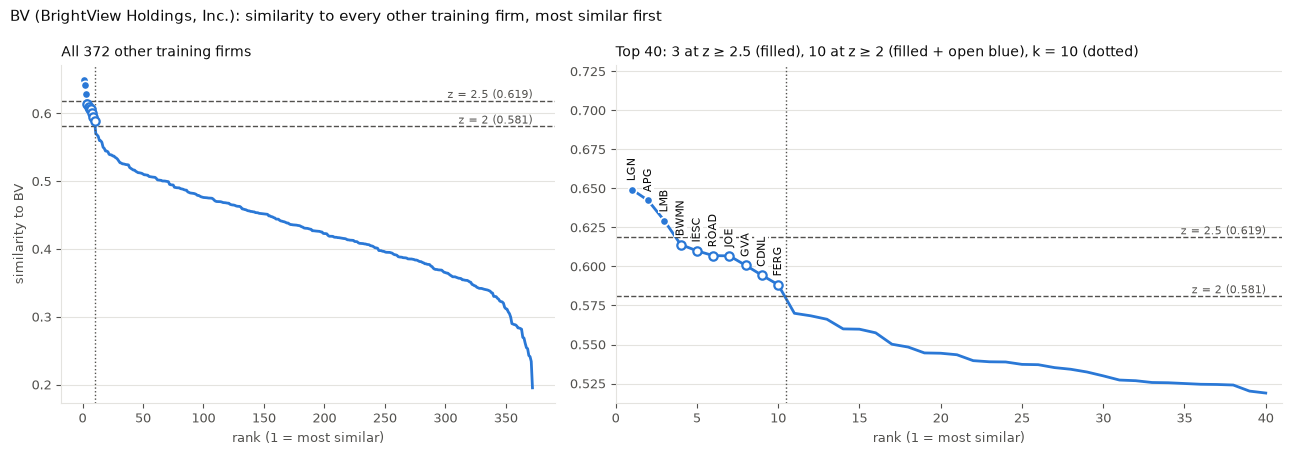

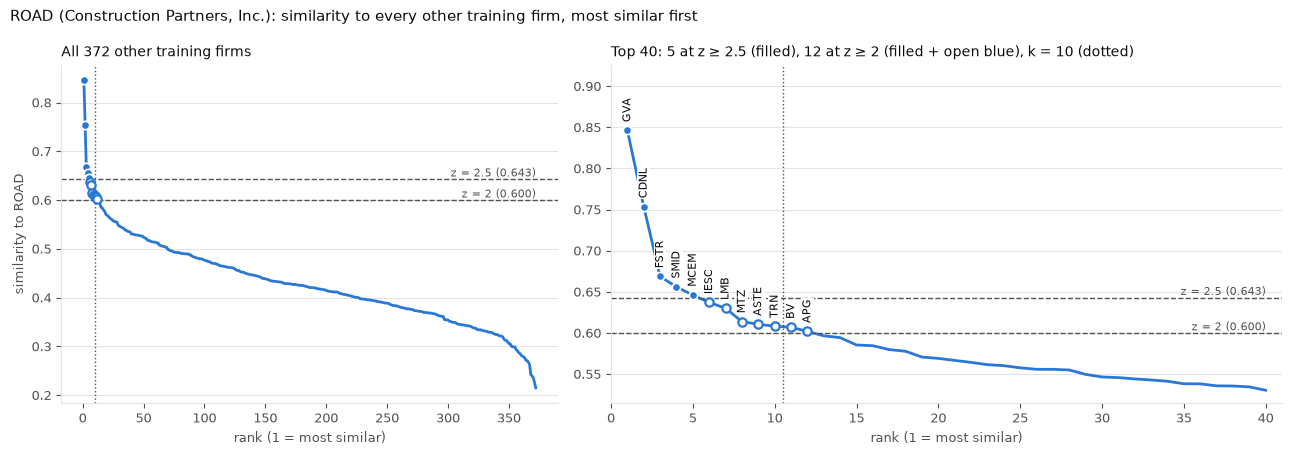

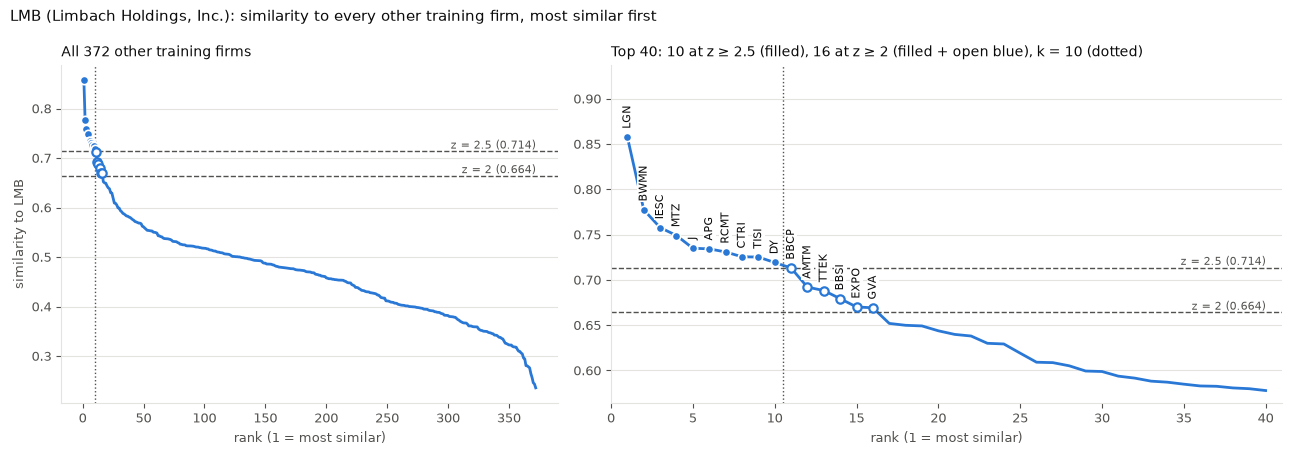

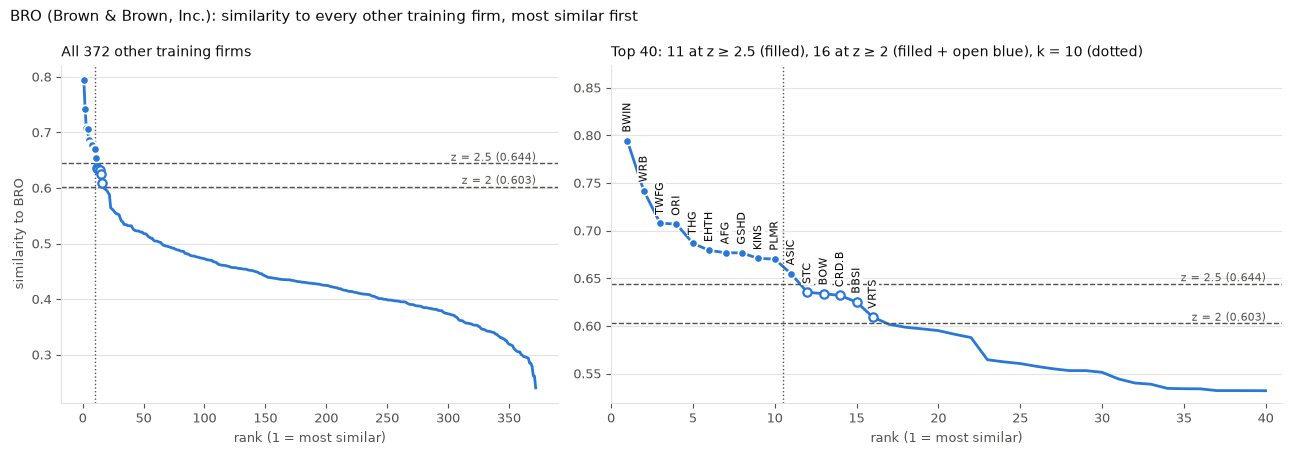

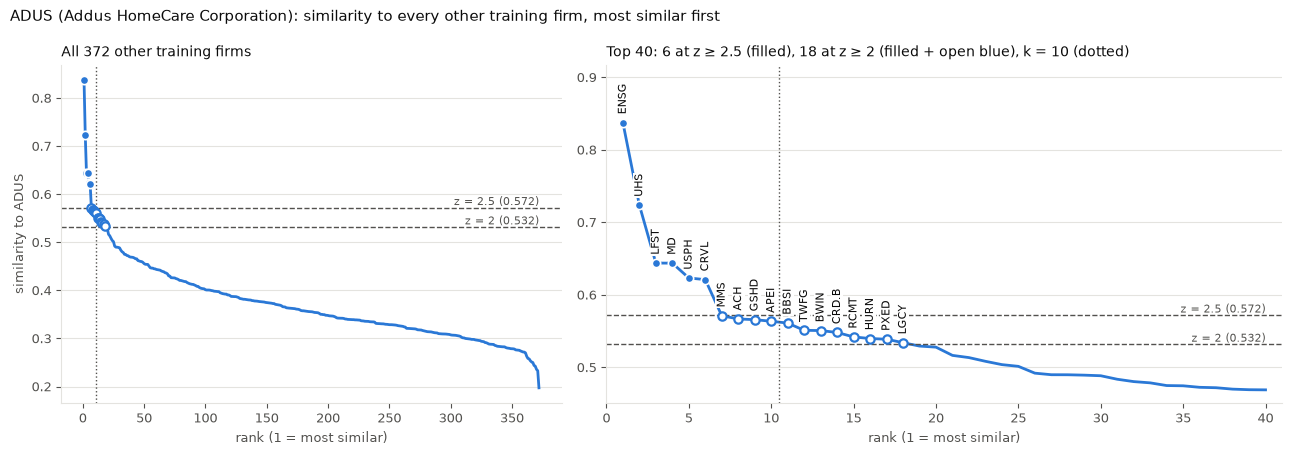

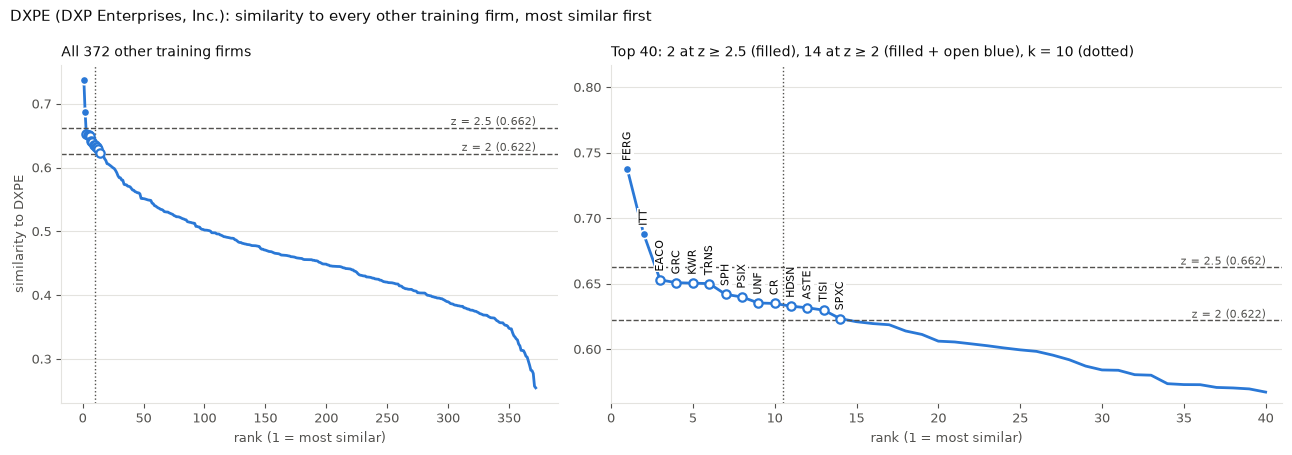

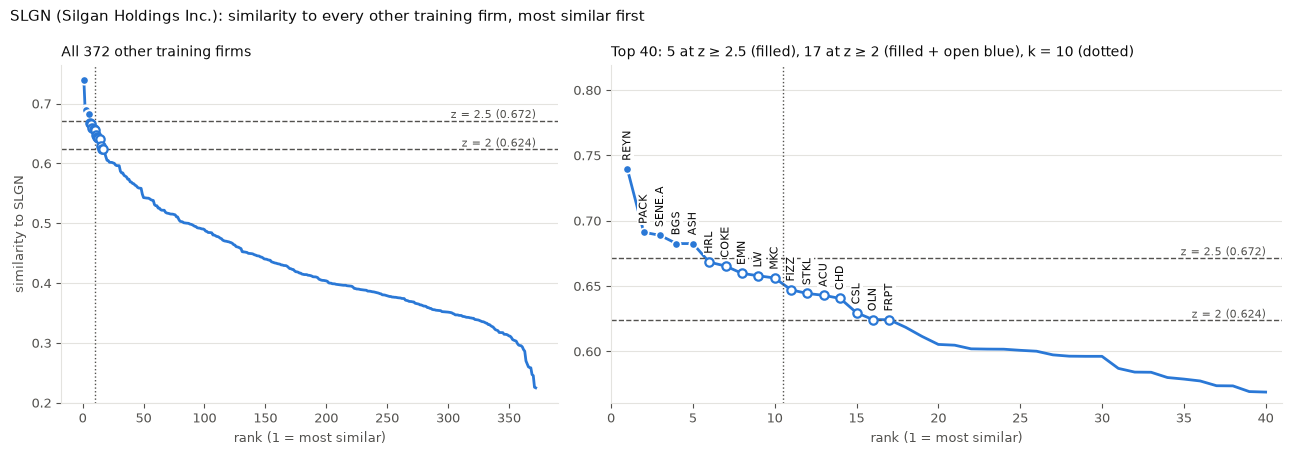

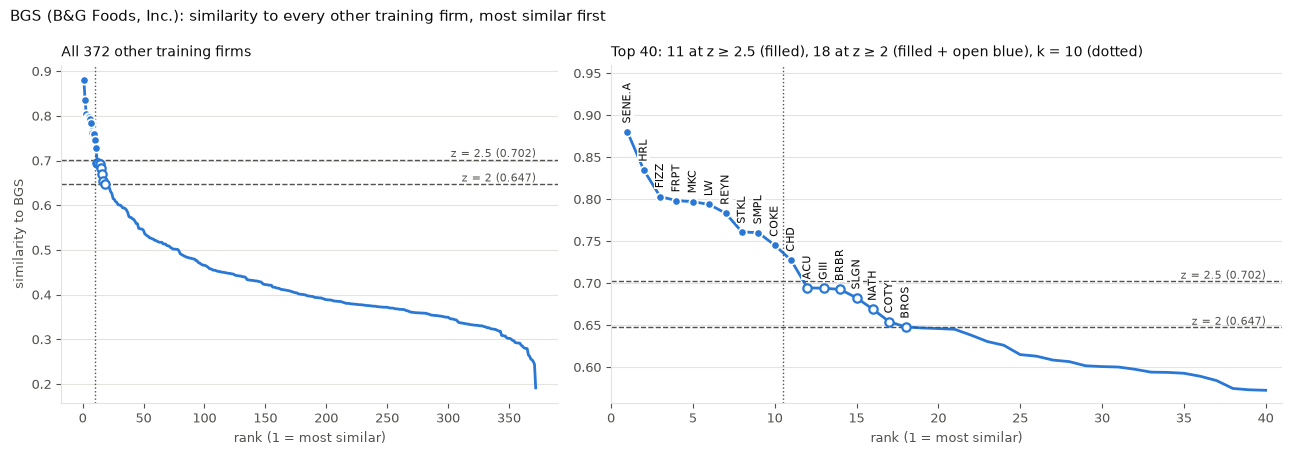

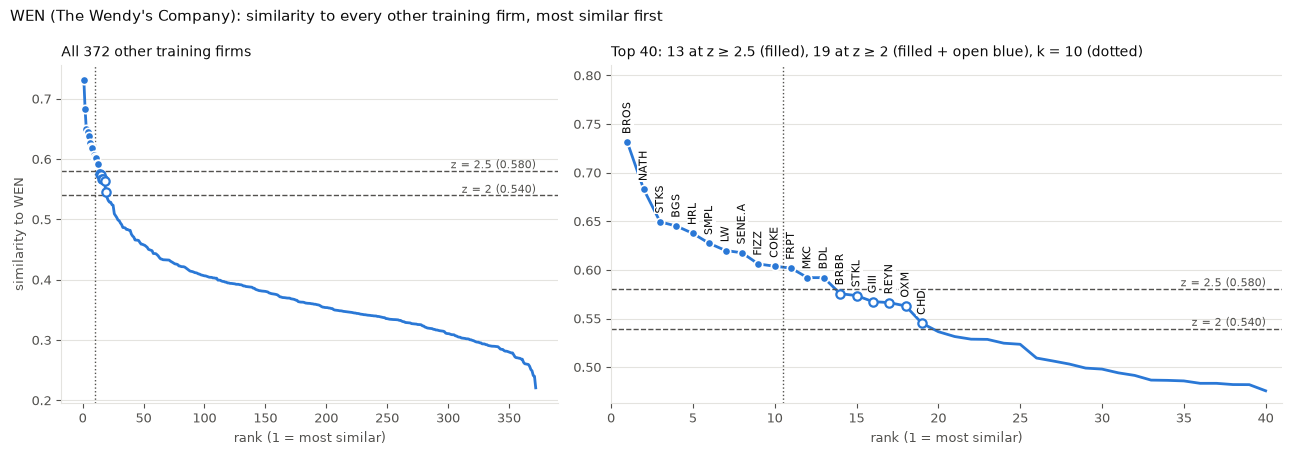

In [9]:
import matplotlib.pyplot as plt

BLUE, INK, MUTED, GRID, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#ffffff"
ZOOM = 40
z_lo, z_hi = min(cd.Z_LEVELS), max(cd.Z_LEVELS)

def falloff(t):
    """Similarity of target t to every pool firm by rank (left) and the top ZOOM with candidates labeled (right)."""
    r = ranking[ranking["target"] == id_of[t]].assign(ticker=lambda d: d["comp"].map(info["target_ciq_ticker"]))
    cuts = {lvl: r["similarity"].mean() + lvl * r["similarity"].std(ddof=0) for lvl in cd.Z_LEVELS}   # z = lvl
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.35]})
    for ax, n in zip(axes, [len(r), ZOOM]):
        v = r.head(n)
        ax.plot(v["rank"], v["similarity"], color=BLUE, lw=2)
        marks = [(v[v["z"] >= z_hi], BLUE, BLUE), (v[(v["z"] >= z_lo) & (v["z"] < z_hi)], SURFACE, BLUE),
                 (v[v["in_top_k"] & (v["z"] < z_lo)], SURFACE, MUTED)]
        for m, face, edge in marks:
            ax.scatter(m["rank"], m["similarity"], s=36, color=face, edgecolor=SURFACE if face == BLUE else edge,
                       linewidth=1.2 if face == BLUE else 1.6, zorder=3)
        for lvl, cut in cuts.items():
            ax.axhline(cut, color=MUTED, lw=1, ls="--")
            ax.text(n, cut, f"z = {lvl:g} ({cut:.3f})", ha="right", va="bottom", color=MUTED, fontsize=8)
        ax.axvline(cd.TOP_K + 0.5, color=MUTED, lw=1, ls=":")
        ax.grid(axis="y", color=GRID, lw=0.8)
        ax.set_axisbelow(True)
        for side in ["top", "right"]:
            ax.spines[side].set_visible(False)
        for side in ["left", "bottom"]:
            ax.spines[side].set_color(GRID)
        ax.tick_params(colors=MUTED, labelsize=9)
        ax.set_xlabel("rank (1 = most similar)", color=MUTED, fontsize=9)
    axes[0].set_ylabel(f"similarity to {t}", color=MUTED, fontsize=9)
    axes[0].set_title(f"All {len(r)} other training firms", loc="left", color=INK, fontsize=10)
    axes[1].set_title(f"Top {ZOOM}: {(r['z'] >= z_hi).sum()} at z ≥ {z_hi:g} (filled), "
                      f"{(r['z'] >= z_lo).sum()} at z ≥ {z_lo:g} (filled + open blue), k = {cd.TOP_K} (dotted)",
                      loc="left", color=INK, fontsize=10)
    axes[1].set_xlim(0, ZOOM + 1)
    axes[1].set_ylim(top=r["similarity"].max() + 0.08)
    for _, c in r[(r["in_top_k"] | (r["z"] >= z_lo)) & (r["rank"] <= ZOOM)].iterrows():
        axes[1].annotate(c["ticker"], (c["rank"], c["similarity"]), xytext=(0, 6), textcoords="offset points",
                         rotation=90, ha="center", va="bottom", fontsize=8, color=INK,
                         bbox=dict(fc=SURFACE, ec="none", pad=0.6))
    fig.suptitle(f"{t} ({info.loc[id_of[t], 'target_company_name']}): similarity to every other training firm, "
                 "most similar first", x=0.01, ha="left", color=INK, fontsize=11)
    fig.tight_layout()
    return fig

for t in SHOWCASE:
    fig = falloff(t)
    fig.savefig(CAND_OUT / f"similarity_falloff_{t}.png", dpi=150)
    plt.show()

**Results, step 4 (2026-10-25).**
- **Candidates per target:** median 14 at z ≥ 2 (range 5-23, none with fewer than 3); median 7 at z ≥ 2.5 (28 targets with fewer than 3).
- **The facets pick up the industry:** 47% of top-10 candidates share the target's 2-digit SIC code, against 7% for random pairs.
- **Clear peer groups** where the business is distinctive: PCTY (ASUR, PAYC, ADP), ROAD (GVA, CDNL), LMB (LGN, IESC, APG), BGS (packaged food). Their curves drop steeply after the first few firms.
- **Mixed lists** where cosine can't tell business models apart within an industry: BRO gets brokers and insurance carriers, WEN restaurants and packaged-food makers, DXPE manufacturers (its distributor peers MSM and DSGR are in the holdout).
- **No peer:** BV's curve is flat; there is no landscaping firm in the universe, so its candidates are contractors.

## 3. The model: an LLM decides which comps are good (recipe step 6)

**Decided 2026-10-25:** Claude Haiku 5.5 marks every z ≥ 2 candidate of every training target **good (1) or bad (0)**, with a reason of one short sentence (`v0/judge_comps.py`, run outside the notebook, like the facet fill).

- **One call per target.** The model reads the target's name, website and twelve facets, then each candidate's, labeled C1, C2, ... in alphabetical order. It sees no similarity, rank, ticker or multiple, so the order says nothing about how close a candidate is.
- **Good** means in the same business as the target (the same main products or services, sold to the same kind of customers, earning money the same way), so its multiple says something about the target's. **Bad** means a different business, even with a shared industry label, customers or technology. Scale matters less than being in the same business.
- **Code checks** that every candidate is answered once, and maps the labels back to companies. Every prompt and raw answer is kept under `outputs-local/comps/judge/runs/`; `tables/judgments.csv` has one row per target-comp pair (score, reason, step 4 rank, similarity and z). The evals notebook will sample its pairs from this table.
- **Training, then holdout:** the prompt (and later any weights fit on these pairs) is changed only by looking at training targets. When it is frozen, the same step runs once on the holdout targets.

Run it with `python v0/judge_comps.py --workers 4` after section 2 has written a candidates run; a rerun skips targets already judged with the same prompt and model.

In [10]:
import judge_comps as jc

JUDGE_TABLE = jc.output_paths(jc.DEFAULT_OUT).tables / "judgments.csv"
judgments = (pd.read_csv(JUDGE_TABLE, dtype={"target": str, "comp": str}) if JUDGE_TABLE.exists()
             else pd.DataFrame(columns=["target", "comp", "score", "reason", "prompt_version"]))
judgments = judgments[judgments["prompt_version"] == jc.PROMPT_VERSION]
z2 = ranking[ranking[f"z_ge_{jc.DEFAULT_Z:g}"]][["target", "comp", "rank", "similarity", "z"]]
judged = z2.merge(judgments[["target", "comp", "score", "reason"]], on=["target", "comp"], how="left")
complete = judged.groupby("target")["score"].apply(lambda s: s.notna().all())
judged = judged[judged["target"].isin(complete[complete].index)]
kept = judged.groupby("target")["score"].sum()
print(f"prompt {jc.PROMPT_VERSION}: {complete.sum()} of {len(complete)} training targets judged, {len(judged)} pairs; "
      f"{int(judged['score'].sum())} good ({judged['score'].mean():.0%})")
print(f"good comps per target: median {kept.median():.0f}, range {kept.min():.0f}-{kept.max():.0f}; "
      f"{(kept == 0).sum()} targets with none")
# does the LLM agree with the cosine ranking? share marked good by step 4 rank
bands = pd.cut(judged["rank"], [0, 1, 3, 5, 10, 1000], labels=["1", "2-3", "4-5", "6-10", "11+"])
judged.groupby(bands, observed=True)["score"].agg(pairs="size", good="mean").round(2)

prompt 2026-10-25a: 373 of 373 training targets judged, 5293 pairs; 663 good (13%)
good comps per target: median 1, range 0-8; 96 targets with none


,pairs,good
rank,,
1,373,0.57
2-3,746,0.28
4-5,746,0.16
6-10,1795,0.06
11+,1633,0.01


The showcase targets: every z ≥ 2 candidate in step 4 order, with the LLM's answer (1 good, 0 bad) and reason.

In [11]:
pd.set_option("display.max_colwidth", 120)
for t in SHOWCASE:
    rows = judged[judged["target"] == id_of[t]].assign(comp_ticker=lambda d: d["comp"].map(info["target_ciq_ticker"]))
    print(f"{t} ({info.loc[id_of[t], 'target_company_name']}): {int(rows['score'].sum())} good of {len(rows)}")
    display(rows[["rank", "comp_ticker", "similarity", "z", "score", "reason"]].set_index("rank")
            .round({"similarity": 3, "z": 2}).astype({"score": int}))

PCTY (Paylocity Holding Corporation): 4 good of 14


,comp_ticker,similarity,z,score,reason
rank,,,,,
1,ASUR,0.855,4.76,1,"Same core business: cloud payroll, HR and tax filing software sold to small and mid-sized employers."
2,PAYC,0.830,4.50,1,"Same core business: cloud HCM, payroll and tax filing sold directly to US employers."
3,ADP,0.761,3.75,1,"Same core business: cloud payroll, HR and tax filing for employers, with per-employee processing fees."
4,ALIT,0.733,3.45,1,"Overlaps on payroll and HR software for employers, though its core is benefits outsourcing aimed at large employers."
5,UPLD,0.683,2.91,0,"Work management, content and records software for enterprises and government; no payroll or HR overlap."
6,SSNC,0.664,2.71,0,Investment management and fund administration software and operations for financial firms; different business.
7,INTU,0.662,2.69,0,"Consumer tax, accounting and personal finance software; payroll is only one part of a different core business."
8,EVCM,0.657,2.64,0,"Vertical software and payments for small service businesses such as salons and gyms, not employer payroll or HR."
9,CXM,0.642,2.48,0,Social media and customer experience platform for enterprise marketing teams; no HR or payroll overlap.


BV (BrightView Holdings, Inc.): 0 good of 10


,comp_ticker,similarity,z,score,reason
rank,,,,,
1,LGN,0.649,2.90,0,"Building mechanical, electrical and controls services for owners; shares commercial customers but not landscape or g..."
2,APG,0.642,2.81,0,"Fire safety and mechanical, electrical and plumbing contracting for buildings; no landscape maintenance or grounds c..."
3,LMB,0.629,2.64,0,"Mechanical, electrical and plumbing contracting for buildings; shares commercial customers but different trade servi..."
4,BWMN,0.614,2.44,0,"Engineering, surveying and planning consulting billed as professional services; does not perform landscape maintenance."
5,IESC,0.610,2.38,0,"Electrical, lighting and data systems contracting and prefabrication; different trade with no landscape work."
6,ROAD,0.607,2.34,0,"Road and highway paving with its own asphalt and aggregates; heavy civil construction, not landscaping services."
7,JOE,0.607,2.34,0,"Owns land, hotels, clubs and resorts and sells lots; a real estate and hospitality business, not a service provider."
8,GVA,0.601,2.26,0,Public highway and water infrastructure construction with quarries and asphalt plants; not landscape maintenance or ...
9,CDNL,0.594,2.18,0,"Site grading, underground utilities and paving for developers; civil construction rather than recurring landscape ma..."


ROAD (Construction Partners, Inc.): 2 good of 12


...

,comp_ticker,similarity,z,score,reason
rank,,,,,
1,REYN,0.740,3.21,0,"Household disposables like foil, wrap and bags sold to retailers; Silgan sells containers to packaged-goods makers."
2,PACK,0.691,2.71,0,Paper void-fill protective packaging for e-commerce shipping; differs from metal and plastic consumer containers and...
3,SENE.A,0.689,2.68,0,"Canned and frozen vegetable processor and food brand owner; Silgan manufactures packaging, not packaged food."
4,BGS,0.683,2.61,0,Branded packaged foods sold to grocers; Silgan manufactures containers and closures for packaged-goods makers.
5,ASH,0.683,2.61,0,Specialty chemical ingredients and additives sold to formulators; Silgan makes packaging containers and closures.
6,HRL,0.668,2.47,0,"Packaged meat and prepared food processor and brand owner; Silgan supplies containers, not food products."
7,COKE,0.665,2.43,0,Beverage bottler and route distributor; Silgan manufactures containers and closures sold to brand owners.
8,EMN,0.660,2.38,0,"Specialty chemicals, polymers and fibers for industrial manufacturers; not container or closure manufacturing."
9,LW,0.658,2.36,0,Frozen potato food processing for restaurants and grocers; Silgan manufactures packaging containers and closures.


BGS (B&G Foods, Inc.): 4 good of 18


,comp_ticker,similarity,z,score,reason
rank,,,,,
1,SENE.A,0.880,4.12,1,"Canned and frozen vegetables and snack foods sold to grocers, matching B&G's core vegetable and snack lines."
2,HRL,0.835,3.71,1,"Branded shelf-stable packaged foods, canned meats and meals sold to the same grocery and foodservice channels, made ..."
3,FIZZ,0.803,3.42,0,Packaged beverages such as sparkling water and sodas differ from B&G's food products.
4,FRPT,0.798,3.38,0,Refrigerated fresh pet food differs from B&G's human packaged foods and spices.
5,MKC,0.797,3.37,1,"Spices, seasonings, hot sauces and condiments sold as grocery brands and to foodservice, closely matching B&G's spic..."
6,LW,0.794,3.33,0,"Mainly french fries and potato products sold to restaurant chains, a foodservice-focused business unlike B&G's groce..."
7,REYN,0.783,3.24,0,"Aluminum foil, wraps and trash bags are household disposables, not food products."
8,STKL,0.761,3.04,0,"Plant-based beverages and fruit ingredients are a beverage-led business, differing from B&G's shelf-stable pantry br..."
9,SMPL,0.760,3.03,1,"Branded shelf-stable snacks and baking mixes sold to grocery and mass retailers via outsourced manufacturing, simila..."


WEN (The Wendy's Company): 2 good of 19


,comp_ticker,similarity,z,score,reason
rank,,,,,
1,BROS,0.731,4.35,1,"Operates and franchises drive-thru quick-service shops selling to consumers, earning royalties, like Wendy's."
2,NATH,0.683,3.76,1,"Franchises quick-service restaurants under its name and earns franchise royalties, similar to Wendy's model."
3,STKS,0.649,3.35,0,"Upscale steakhouse and Japanese dining with event business, not quick-service burgers."
4,BGS,0.645,3.29,0,"Shelf-stable and frozen packaged grocery foods sold through retailers, not restaurant operations or franchising."
5,HRL,0.638,3.20,0,"Packaged meat processor selling to grocers and foodservice, not a restaurant operator."
6,SMPL,0.627,3.08,0,"Branded protein snacks and shakes sold through retail, with no restaurant operations."
7,LW,0.620,2.98,0,"Frozen potato supplier that sells french fries to quick-service chains; an ingredient maker, not a restaurant operator."
8,SENE.A,0.618,2.96,0,"Canned and frozen vegetable processor selling to grocers, not restaurants."
9,FIZZ,0.606,2.81,0,"Packaged sparkling water and soft drinks sold to retailers, not restaurants."


**Results, step 6 (prompt 2026-10-25a, about $0.57).**
- **373 targets, 5,293 pairs; 663 marked good (13%).** Median 1 good comp per target; 96 targets with none.
- **It mostly agrees with the cosine order:** 57% of rank-1 candidates are good, 28% at ranks 2-3, 16% at 4-5, 6% at 6-10, 1% past 10.
- **It separates business models that cosine mixes:** BRO keeps the brokers (BWIN, TWFG, GSHD, EHTH) and drops every carrier; WEN keeps the franchisors (BROS, NATH); DXPE keeps the distributors (FERG, TRNS); PCTY keeps ASUR, PAYC, ADP and ALIT.
- **It is strict:** BV and SLGN get no good comp, and ADUS keeps only ENSG.

## 4. Comps without embeddings

Two ways to find comps that skip the embedding shortlist of section 2, to see whether it helps or hurts:

- **The LLM suggests comps directly** (`v0/suggest_comps.py`, Claude Haiku 5.5, prompt 2026-10-25a). Every call holds the whole training pool: all 373 firms, labeled P001, ... in alphabetical order, each with its name, website and the facets that say what business it is in (core offering, products, services, customers, revenue model). The pool is the same for every target, so it is cached (about 99k tokens; a call after the first pays a tenth for it). Then comes the target, with all twelve facets. The model picks **at most ten companies in the same business, best first**, each with a reason; code drops the target itself, unknown labels and repeats. Run it with `python v0/suggest_comps.py --workers 4`.
- **Same SIC code**, no model at all: every other training firm with the target's 4-, 3- or 2-digit SIC code (from the company list).

Both are scored in section 6 with equal weights (there is no similarity to weight by).

In [12]:
import suggest_comps as sg

SUGGEST_TABLE = sg.output_paths(sg.DEFAULT_OUT).tables / "suggestions.csv"
suggestions = (pd.read_csv(SUGGEST_TABLE, dtype={"target": str, "comp": str}) if SUGGEST_TABLE.exists()
               else pd.DataFrame(columns=["target", "rank", "comp", "reason", "prompt_version"]))
suggestions = suggestions[suggestions["prompt_version"] == sg.PROMPT_VERSION]
direct = suggestions.dropna(subset=["comp"])[["target", "rank", "comp", "reason"]]
asked = sorted(set(suggestions["target"]))
n_direct = direct.groupby("target").size().reindex(asked, fill_value=0)
print(f"LLM direct, prompt {sg.PROMPT_VERSION}: {len(asked)} of {len(training)} training targets asked, "
      f"{len(direct)} comps; median {n_direct.median():.0f} per target, {(n_direct == 0).sum()} targets with none")

# where the LLM's own picks sit in the cosine ranking, and what the step 6 judge said about them
where = (direct.merge(ranking[["target", "comp", "rank", "z"]].rename(columns={"rank": "cosine_rank"}),
                      on=["target", "comp"], how="left")
         .merge(judged[["target", "comp", "score"]].rename(columns={"score": "judge_good"}),
                on=["target", "comp"], how="left"))
print(f"of the LLM's direct picks: {(where['z'] >= 2).mean():.0%} are cosine candidates at z >= 2, "
      f"median cosine rank {where['cosine_rank'].median():.0f}, {(where['cosine_rank'] > 20).mean():.0%} past rank 20; "
      f"{where['judge_good'].eq(1).mean():.0%} were also marked good in step 6")

# same-SIC peers: every other training firm sharing the code
tr = info.loc[training].reset_index()
sic_pairs = {}
for level, col in [("SIC4", "target_sic4_code"), ("SIC3", "target_sic3_code"), ("SIC2", "target_sic2_code")]:
    m = tr[["IQ_COMPANY_ID", col]].merge(tr[["IQ_COMPANY_ID", col]], on=col, suffixes=("_t", "_c"))
    m = m[m["IQ_COMPANY_ID_t"] != m["IQ_COMPANY_ID_c"]]
    sic_pairs[level] = m.rename(columns={"IQ_COMPANY_ID_t": "target", "IQ_COMPANY_ID_c": "comp"})[["target", "comp"]]
    n = sic_pairs[level].groupby("target").size().reindex(training, fill_value=0)
    print(f"same {level}: median {n.median():.0f} peers per target, {(n == 0).sum()} targets with none")

LLM direct, prompt 2026-10-25a: 373 of 373 training targets asked, 1194 comps; median 3 per target, 32 targets with none
of the LLM's direct picks: 89% are cosine candidates at z >= 2, median cosine rank 3, 8% past rank 20; 54% were also marked good in step 6
same SIC4: median 2 peers per target, 73 targets with none
same SIC3: median 4 peers per target, 45 targets with none
same SIC2: median 12 peers per target, 6 targets with none


The showcase targets: the LLM's direct picks, best first, with where each sits in the cosine ranking (section 2) and whether step 6 marked it good (blank: not a z ≥ 2 candidate, so step 6 never saw it).

In [13]:
show = where[where["target"].isin([id_of[t] for t in SHOWCASE])].assign(
    target_ticker=lambda d: d["target"].map(info["target_ciq_ticker"]),
    comp_ticker=lambda d: d["comp"].map(info["target_ciq_ticker"]))
for t in SHOWCASE:
    rows = show[show["target_ticker"] == t]
    print(f"{t}: {len(rows)} picks")
    if len(rows):
        display(rows[["rank", "comp_ticker", "cosine_rank", "z", "judge_good", "reason"]].set_index("rank")
                .round({"z": 2}))

PCTY: 5 picks


,comp_ticker,cosine_rank,z,judge_good,reason
rank,,,,,
1.0,PAYC,2,4.50,1.0,"Sells cloud HCM software with payroll, HR and time modules to US employers, plus payroll processing and tax filing, ..."
2.0,ADP,3,3.75,1.0,"Provides cloud payroll, HR and benefits software plus outsourced payroll and tax filing to employers, the same core ..."
3.0,ASUR,1,4.76,1.0,"Sells subscription HCM software covering payroll, HR and time to small and mid-sized employers, with payroll process..."
4.0,ALIT,4,3.45,1.0,"Delivers cloud human capital software and outsourced payroll and benefits administration to large employers, overlap..."
5.0,BBSI,15,1.97,NaN,"Provides outsourced payroll and HR administration to small and mid-sized businesses, billed per employee, though thr..."


BV: 0 picks
ROAD: 2 picks


,comp_ticker,cosine_rank,z,judge_good,reason
rank,,,,,
1.0,GVA,1,4.86,1.0,"Builds highways, bridges and water infrastructure for public agencies while producing its own aggregates, asphalt an..."
2.0,CDNL,2,3.79,1.0,"Self-performs grading, paving and site development for municipal and developer projects, and sells its own asphalt a..."


LMB: 3 picks


...

,comp_ticker,cosine_rank,z,judge_good,reason
rank,,,,,
1.0,KWR,5,2.35,0.0,Sells process fluids and lubricants to industrial plants and provides onsite fluid management and technical services...
2.0,TISI,13,2.10,0.0,"Performs repair, inspection and maintenance services on rotating and process equipment inside refineries and plants ..."
3.0,TRNS,6,2.35,1.0,Distributes test and calibration instruments to industrial plants and pairs product sales with repair and asset mana...
4.0,FERG,1,3.42,1.0,"Distributes plumbing, waterworks and industrial pipe, valves and fittings through a branch network with fabrication ..."
5.0,HDSN,11,2.13,0.0,Distributes refrigerants and equipment to contractors and facility operators while providing reclamation and recover...


SLGN: 0 picks
BGS: 7 picks


,comp_ticker,cosine_rank,z,judge_good,reason
rank,,,,,
1.0,MKC,5,3.37,1.0,"Makes and sells branded spices, seasonings, condiments and sauces through grocery retailers, the same core pantry-fo..."
2.0,SENE.A,1,4.12,1.0,Processes and sells branded and private-label canned and frozen vegetables and snack foods to grocery retailers.
3.0,HRL,2,3.71,1.0,"Markets branded packaged meats, shelf-stable meals and refrigerated foods through grocery retailers and foodservice ..."
4.0,SMPL,9,3.03,1.0,"Sells branded protein and low-carb snacks and shakes through grocery and mass retailers, outsourcing manufacturing a..."
5.0,LW,6,3.33,0.0,"Produces frozen potato products sold to foodservice and retail grocery customers, overlapping B&G's frozen vegetable..."
6.0,BRBR,14,2.41,0.0,"Sells branded protein shakes, powders and bars through retailers, using outsourced manufacturing and a brand-owner m..."
7.0,NATH,16,2.20,0.0,Licenses and sells its branded hot dogs and meat products through retail grocery and foodservice channels.


WEN: 3 picks


,comp_ticker,cosine_rank,z,judge_good,reason
rank,,,,,
1.0,BROS,1,4.35,1.0,Operates and franchises drive-thru quick-service restaurants selling handcrafted drinks and food directly to consume...
2.0,NATH,2,3.76,1.0,"Franchises quick-service restaurants under its brand and earns franchise fees and royalties, alongside company-opera..."
3.0,BDL,13,2.64,0.0,"Operates consumer restaurants and franchises its brand, earning food sales, franchise royalties and rent from leased..."


**Results, comps without embeddings (prompt 2026-10-25a, about $0.55).**
- **LLM direct:** 1,194 picks, median 3 per target; 32 targets with none (BV, SLGN among them).
- **The embedding shortlist rarely hides a comp the LLM would choose:** 89% of the direct picks are cosine candidates at z ≥ 2 anyway (median cosine rank 3; 8% past rank 20).
- **The two original LLM selection rules agree on about half (LLM→cosine retains the direct picks):** 54% of the direct picks were also marked good in step 6.
- **Same SIC:** SIC4 gives a median of 2 peers (73 targets with none), SIC3 4 (45 with none), SIC2 12 (6 with none).

## 5. LLM then cosine

The LLM's direct selections from section 4 are fixed first. Cosine scores from the full section 2 ranking then reorder those selected peers (`v0/llm_then_cosine.py`); section 6 uses the same scores as valuation weights. There is no z-score cutoff and no new model call. Because the LLM chose at most ten peers and this method keeps up to ten, it changes neither the peer set nor target coverage.

The `reason` for each pair comes from the saved direct LLM answer in `suggestions.csv`. It explains the LLM's original choice; cosine does not generate reasons.


In [14]:
import llm_then_cosine as lc

reverse = lc.rank_selected(direct, ranking, max_peers=sg.MAX_COMPS)
assert len(reverse) == len(direct)
changed = int(reverse["rank"].ne(reverse["llm_rank"]).sum())
print(f"{len(reverse)} peers for {reverse['target'].nunique()} of {len(training)} training targets; "
      f"{changed} positions changed; no peer for {len(training) - reverse['target'].nunique()} targets")

HYBRID_OUT = COMPS_OUT / "llm_then_cosine" / RUN
HYBRID_OUT.mkdir(parents=True, exist_ok=True)
reverse.to_csv(HYBRID_OUT / "pairs.csv", index=False)


1194 peers for 341 of 373 training targets; 696 positions changed; no peer for 32 targets


The showcase targets: the new rank among the LLM-selected peers, the LLM's original rank, the peer's rank against the full cosine pool, and the original LLM reason.


In [15]:
for t in SHOWCASE:
    rows = reverse[reverse["target"] == id_of[t]].assign(
        comp_ticker=lambda d: d["comp"].map(info["target_ciq_ticker"]))
    print(f"{t}: {len(rows)} selected peers")
    if len(rows):
        display(rows[["rank", "llm_rank", "comp_ticker", "cosine_rank", "similarity", "z", "reason"]]
                .set_index("rank").round({"similarity": 3, "z": 2}))


PCTY: 5 selected peers


,llm_rank,comp_ticker,cosine_rank,similarity,z,reason
rank,,,,,,
1,3.0,ASUR,1,0.855,4.76,Sells subscription HCM software covering payro...
2,1.0,PAYC,2,0.830,4.50,"Sells cloud HCM software with payroll, HR and ..."
3,2.0,ADP,3,0.761,3.75,"Provides cloud payroll, HR and benefits softwa..."
4,4.0,ALIT,4,0.733,3.45,Delivers cloud human capital software and outs...
5,5.0,BBSI,15,0.595,1.97,Provides outsourced payroll and HR administrat...


BV: 0 selected peers


ROAD: 2 selected peers


,llm_rank,comp_ticker,cosine_rank,similarity,z,reason
rank,,,,,,
1,1.0,GVA,1,0.846,4.86,"Builds highways, bridges and water infrastruct..."
2,2.0,CDNL,2,0.754,3.79,"Self-performs grading, paving and site develop..."


...

SLGN: 0 selected peers


BGS: 7 selected peers


,llm_rank,comp_ticker,cosine_rank,similarity,z,reason
rank,,,,,,
1,2.0,SENE.A,1,0.880,4.12,Processes and sells branded and private-label ...
2,3.0,HRL,2,0.835,3.71,"Markets branded packaged meats, shelf-stable m..."
3,1.0,MKC,5,0.797,3.37,"Makes and sells branded spices, seasonings, co..."
4,5.0,LW,6,0.794,3.33,Produces frozen potato products sold to foodse...
5,4.0,SMPL,9,0.760,3.03,Sells branded protein and low-carb snacks and ...
6,6.0,BRBR,14,0.693,2.41,"Sells branded protein shakes, powders and bars..."
7,7.0,NATH,16,0.669,2.20,Licenses and sells its branded hot dogs and me...


WEN: 3 selected peers


,llm_rank,comp_ticker,cosine_rank,similarity,z,reason
rank,,,,,,
1,1.0,BROS,1,0.731,4.35,Operates and franchises drive-thru quick-servi...
2,2.0,NATH,2,0.683,3.76,Franchises quick-service restaurants under its...
3,3.0,BDL,13,0.592,2.64,Operates consumer restaurants and franchises i...


**Results, LLM then cosine (saved v0 inputs, 2026-10-27).** The method retains all 1,194 direct LLM picks for 341 of 373 training targets; 32 targets still have no peer. Cosine changes 696 within-target rank positions. For the ten showcase targets, eight have 31 picks and 14 positions change. The reasons are unchanged LLM responses, not new evidence. Valuation results follow in section 6.


## 6. Step 7: estimates against the actual multiples

**The ground truth** is each target's actual EV/EBITDA, from the financials table. This is the first place the multiples are read (`v0/valuation.py`).

**The estimate (step 7)** is a weighted average of the comps' EV/EBITDA; the median is shown too, for comparison with pre-v0. The comp rules compared:
- **No matching:** the median multiple of all the other training firms. Any comp rule has to beat it. In pre-v0 every matching method came out at about 35% median absolute error, the same as no matching (34.6%).
- **Cosine only (no LLM):** the step 4 candidates (top 10, z ≥ 2 or z ≥ 2.5), weighted by their similarity.
- **Cosine then LLM (LLM good comps):** the z ≥ 2 candidates the LLM marked good (section 3), weighted by their similarity. The like-for-like comparison is with **cosine z ≥ 2**: the same candidates, without the LLM's choice.
- **Without embeddings** (section 4): the LLM's direct picks, and same-SIC peers, with equal weights.
- **LLM then cosine** (section 5): the direct LLM picks, weighted by cosine similarity.

**Which targets each row scores:** every rule runs on all 373 training targets. A rule that finds no comp for a target gives it no estimate (the `targets` column counts the rest): the LLM marks no candidate good for some targets, and finds no same-business comp for others (BV, SLGN). So the second table scores every rule on the same targets, those where **both original LLM selection rules and LLM→cosine** give an estimate, and its rows can be compared directly.

**Measures:** median absolute % error, % of targets within 25%, Spearman (estimate, actual), and % of targets closer than with no matching. They are computed here for the **training targets** (development). The holdout is scored once, at the end.

In [16]:
ev = financials["target_ev_to_ebitda"]          # the answer key: first read here
actual = ev[training]
NO_MATCH = "no matching (median of the other training firms)"
results = {NO_MATCH: vl.no_matching(training, training, ev)}
for name, pairs in {"top 10": ranking[ranking["in_top_k"]],
                    **{f"z ≥ {lvl:g}": ranking[ranking[f"z_ge_{lvl:g}"]] for lvl in cd.Z_LEVELS}}.items():
    results[f"cosine {name}, similarity-weighted mean"] = vl.estimate(pairs, ev, weight="similarity")
    results[f"cosine {name}, median"] = vl.estimate(pairs, ev, how="median")
LLM_RULE = "LLM good comps (from z ≥ 2), similarity-weighted mean"
good = judged[judged["score"] == 1]
if len(good):
    results[LLM_RULE] = vl.estimate(good, ev, weight="similarity")
    results["LLM good comps (from z ≥ 2), median"] = vl.estimate(good, ev, how="median")
DIRECT_RULE = "LLM suggests directly (no embeddings), mean"
if len(direct):
    results[DIRECT_RULE] = vl.estimate(direct, ev)
    results["LLM suggests directly (no embeddings), median"] = vl.estimate(direct, ev, how="median")
HYBRID_RULE = "LLM then cosine, similarity-weighted mean"
results[HYBRID_RULE] = vl.estimate(reverse, ev, weight="similarity")
for level, pairs in sic_pairs.items():
    results[f"same {level} (no embeddings, no LLM), mean"] = vl.estimate(pairs, ev)
evaluation = vl.summary(results, actual, baseline=NO_MATCH)
print(f"{len(training)} training targets; comps from the other training firms")
evaluation.round(2)

373 training targets; comps from the other training firms


,targets,comps per target (median),median abs % error,% within 25%,"Spearman(estimate, actual)",% closer than no matching
comp rule,,,,,,
no matching (median of the other training firms),373,372.0,32.68,38.61,NaN,NaN
"cosine top 10, similarity-weighted mean",373,10.0,31.12,41.02,0.38,52.28
"cosine top 10, median",373,10.0,30.61,42.36,0.35,55.50
"cosine z ≥ 2, similarity-weighted mean",373,14.0,32.43,41.29,0.36,52.28
"cosine z ≥ 2, median",373,14.0,31.64,42.09,0.32,56.03
"cosine z ≥ 2.5, similarity-weighted mean",372,7.0,30.77,41.94,0.39,54.84
"cosine z ≥ 2.5, median",372,7.0,32.29,38.44,0.33,54.30
"LLM good comps (from z ≥ 2), similarity-weighted mean",277,2.0,31.08,41.16,0.39,52.71
"LLM good comps (from z ≥ 2), median",277,2.0,30.75,41.52,0.40,52.35


The same rules on the targets where both original LLM selection rules and LLM→cosine give an estimate, so every row is scored on the same companies. (Same-SIC rows can still have fewer, where a target has no same-code peer.)

In [17]:
covered = pd.Index(training)
for rule in (LLM_RULE, DIRECT_RULE, HYBRID_RULE):
    covered = covered.intersection(results[rule].index) if rule in results else pd.Index([])
evaluation_covered = vl.summary({k: v.loc[v.index.intersection(covered)] for k, v in results.items()},
                                actual[covered], baseline=NO_MATCH) if len(covered) else pd.DataFrame()
print(f"{len(covered)} of {len(training)} training targets have an estimate from all three LLM-containing routes")
evaluation_covered.round(2)

277 of 373 training targets have an estimate from all three LLM-containing routes


,targets,comps per target (median),median abs % error,% within 25%,"Spearman(estimate, actual)",% closer than no matching
comp rule,,,,,,
no matching (median of the other training firms),277,372.0,31.88,40.07,NaN,NaN
"cosine top 10, similarity-weighted mean",277,10.0,30.21,41.88,0.42,52.71
"cosine top 10, median",277,10.0,31.35,41.52,0.40,55.60
"cosine z ≥ 2, similarity-weighted mean",277,14.0,31.07,42.60,0.40,53.07
"cosine z ≥ 2, median",277,14.0,32.19,41.52,0.37,57.40
"cosine z ≥ 2.5, similarity-weighted mean",277,7.0,30.16,42.96,0.45,55.96
"cosine z ≥ 2.5, median",277,7.0,32.22,40.07,0.39,56.68
"LLM good comps (from z ≥ 2), similarity-weighted mean",277,2.0,31.08,41.16,0.39,52.71
"LLM good comps (from z ≥ 2), median",277,2.0,30.75,41.52,0.40,52.35


The showcase targets: actual multiple, and each rule's estimate and error (% of actual).

In [18]:
per_target = pd.concat({name: vl.errors(r, actual) for name, r in results.items()},
                       names=["comp rule", "IQ_COMPANY_ID"]).reset_index()
per_target.insert(2, "ticker", per_target["IQ_COMPANY_ID"].map(info["target_ciq_ticker"]))
show = per_target[per_target["ticker"].isin(SHOWCASE)]
SHOW_RULES = [NO_MATCH, "cosine z ≥ 2, similarity-weighted mean", LLM_RULE, DIRECT_RULE, HYBRID_RULE]
wide = show[show["comp rule"].isin(SHOW_RULES)].pivot(index="ticker", columns="comp rule",
                                                       values=["estimate", "error %"])
wide = wide.reindex(SHOWCASE).reindex(columns=SHOW_RULES, level=1)
wide.insert(0, ("actual", ""), actual.rename(index=info["target_ciq_ticker"]).reindex(SHOWCASE))
wide.round(1)

actual  ...                                   error %
comp rule         ... LLM then cosine, similarity-weighted mean
ticker            ...                                          
PCTY        22.1  ...                                     -37.0
BV           6.7  ...                                       NaN
ROAD        16.5  ...                                     -43.3
LMB         14.2  ...                                       9.7
BRO         17.7  ...                                     -13.5
ADUS        12.0  ...                                      12.7
DXPE         9.9  ...                                       1.4
SLGN         8.2  ...                                       NaN
BGS          8.3  ...                                      20.0
WEN         10.2  ...                                      51.4

[10 rows x 11 columns]

**Results, step 7 (training targets, 2026-10-25).**
- **All 373 targets:** no matching 32.7% median absolute error; cosine 30.6-32.4%; LLM good comps 31.1% (on the 277 it covers); LLM direct 33.0% (341); LLM→cosine 32.7% (the same 341); same SIC 34.1-35.1%.
- **On the 277 targets all four baseline routes cover:** cosine z ≥ 2.5 30.2% (Spearman 0.45), LLM direct 30.8% (0.36), LLM→cosine 30.6%, cosine→LLM good comps 31.1% (0.39), cosine z ≥ 2 31.1% (0.40), no matching 31.9%, same SIC 33.1-34.4% (0.28-0.30).
- **Every way of choosing comps lands within about 30-33%,** as in pre-v0: embeddings, the LLM, or both in either order. Same-SIC peers are the worst, below no matching.
- **The right peers can still miss:** WEN is +94% with BROS and NATH, ADUS +28% with ENSG alone; BRO improves most with the LLM's comps (-39% to -14%).
- **What this points to:** choosing comps doesn't look like the bottleneck. Next candidates are the estimate rule (weights fit on training pairs, scale, shrinking toward the all-firm median) and a rule for targets with no comp.


In [19]:
VAL_OUT = COMPS_OUT / "valuation" / RUN
VAL_OUT.mkdir(parents=True, exist_ok=True)
evaluation.to_csv(VAL_OUT / "summary.csv")
evaluation_covered.to_csv(VAL_OUT / "summary_llm_covered.csv")
per_target.to_csv(VAL_OUT / "per_target.csv", index=False)
(VAL_OUT / "run.json").write_text(json.dumps({
    "run": RUN, "candidates_run": CAND_OUT.name, "split_run": SPLIT_OUT.name,
    "targets": "training", "pool": "training (not the target itself)", "rules": list(results),
    "baseline": NO_MATCH, "llm_rule": LLM_RULE, "llm_prompt_version": jc.PROMPT_VERSION,
    "llm_targets_judged": int(complete.sum()), "direct_prompt_version": sg.PROMPT_VERSION,
    "direct_targets_asked": len(asked), "targets_both_llm_rules": len(covered),
}, indent=1, ensure_ascii=False), encoding="utf-8")
print("wrote", VAL_OUT.relative_to(ROOT))

wrote

 outputs-local\comps\valuation\20261025T080854Z
